In [1]:
%load_ext autoreload
%autoreload 2

%load_ext sql
%sql duckdb:///:memory:

%sql create or replace view V_SERIATIM as select * from read_parquet('../../mort_data/V_SERIATIM.parquet')
%sql create or replace view V_GROUP_RESPONSE as select * from read_parquet('../../mort_data/V_GROUP_RESPONSE.parquet')

import sys
sys.path.insert(0, "../../")

import formulaic as frm, pandas as pd, numpy as np


The 'toml' package isn't installed. To load settings from pyproject.toml or ~/.jupysql/config, install with: pip install toml

Connecting to 'duckdb:///:memory:'

Running query in 'duckdb:///:memory:'

Running query in 'duckdb:///:memory:'

# Individual Models from Grouped Data

Working with grouped response data and individual level predictors is an unusual problem.  Fortunately, the same simple math that applies to deep-learning and many other complex machine learning problems also applies here.  We can make use of the **chain rule** from calculus to estimate individual level predictions, even though our claims are aggregated to the group level.

Here is how it works in a nutshell:

 * The group's claims are just the sum of the individual claims:  
 
 $$
 \text{Group Claims}_i = \sum_j \text{individual claims}_{i,j}
 $$

* We can (theoretically) predict individual claims using a GLM model (with INDIVIDUAL exposures / offsets) IF we know the $\beta$'s.

$$
\text{individual claims} = \text{policies exposed} \times \exp \big[ \beta_0 + \beta_1 \times \text{age} + \beta_1 \times \text{gender} \big]
$$

* so we just need to solve the equation (for the $\beta$'s).  Hard for humans, but easy for computers!

 $$
 \sum \text{Group Claims} = \sum \bigg[ \text{policies exposed} \times \exp \big[ \beta_0 + \beta_1 \times \text{age} + \beta_1 \times \text{gender} \big] \bigg]
 $$

* Since this is a smooth function when we apply Poisson Likelihood, we can use any smooth function optimizer (there are many choices).  [L-BFGS](https://en.wikipedia.org/wiki/Limited-memory_BFGS) is usually a very powerful option, and it's bundled in [scipy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html).  Even better, we can apply monotonic constraints with it (e.g., only positive coefficients).

  * L-BFGS is our "default" choice of optimizer, when one is necessary. There is a [jax implementation](https://jaxopt.github.io/stable/_autosummary/jaxopt.LBFGS.html) and [bounded jax implementation](https://jaxopt.github.io/stable/_autosummary/jaxopt.LBFGSB.html) that provide GPU-based solving when a need arises.  Generally speaking we should start with the scipy implementation.

  * L-BFGS-B is version that allows for simple constraints (called bounds) on coefficients, e.g. montonically increasing or maximum values. Not sure if it allows constrains on linear combinations of coefficients.


### 

### Simulated Group Data

The data is drawn randomly from the ILEC dataset, which is a real, public-use dataset of insurance claims.  It's seriatim-ish in many places.  We can simulate groups by first choosing a group size, and then assigning the cell to that group in that year. 

Here are the group sizes in the training data:



Running query in 'duckdb:///:memory:'

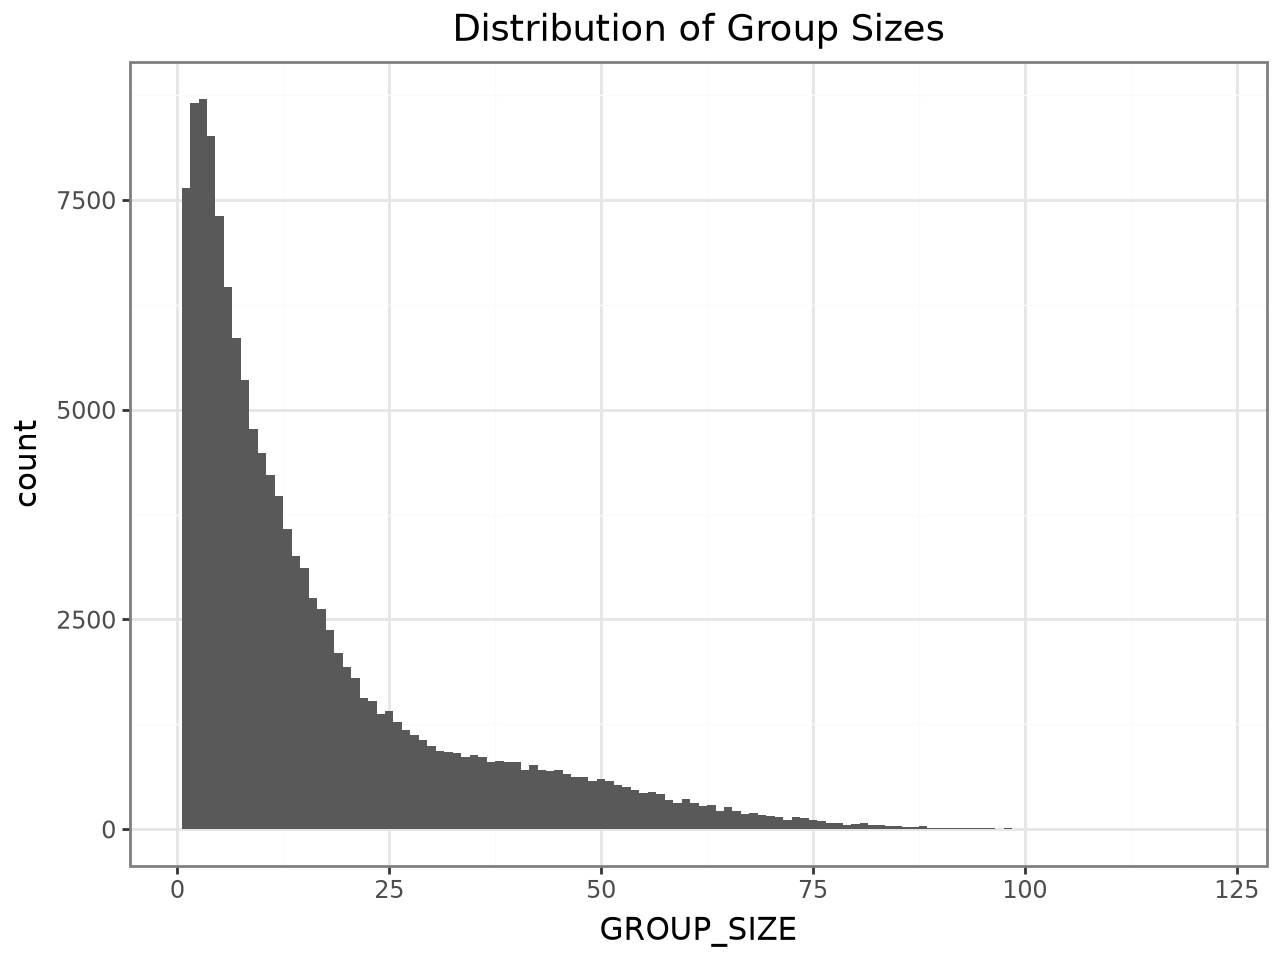

In [2]:
import plotnine as p9

df_group_sizes = %sql select GROUP_ID, count(1) as GROUP_SIZE from V_SERIATIM group by GROUP_ID
df_group_sizes = df_group_sizes.DataFrame()

(
    p9.ggplot(df_group_sizes, p9.aes(x="GROUP_SIZE"))
    + p9.geom_histogram(binwidth=1)
    + p9.theme_bw()
    + p9.labs(title="Distribution of Group Sizes")
)

Each group consists of a number of cells, which are sampled from the ILEC data so that they are pretty small, let's look at the average number of unique cells (age, product, observation year, gender, duration, etc) and the average exposure, to ensure we are getting something close to a random group of heterogenous exposures:

Running query in 'duckdb:///:memory:'

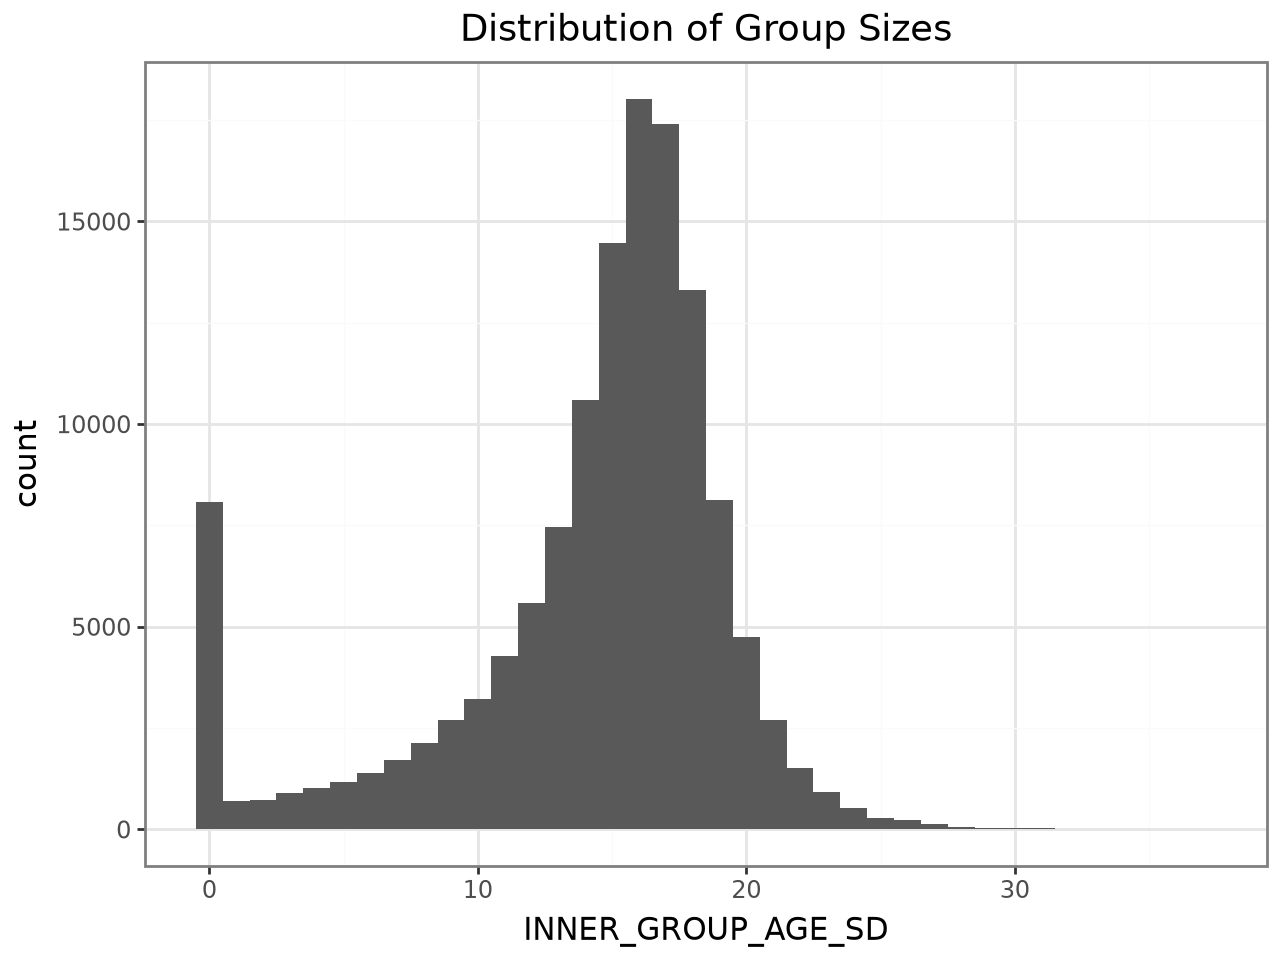

In [3]:
df_group_age_sd =  %sql select GROUP_ID, STDDEV_POP(ATTAINED_AGE) as INNER_GROUP_AGE_SD from V_SERIATIM group by GROUP_ID
df_group_age_sd = df_group_age_sd.DataFrame()

(
    p9.ggplot(df_group_age_sd, p9.aes(x="INNER_GROUP_AGE_SD"))
    + p9.geom_histogram(binwidth=1)
    + p9.theme_bw()
    + p9.labs(title="Distribution of Group Sizes")
)


### Experiment

We'll create simulated grouped data and fit an individual-level GLM to it.

 * Once you've run through this notebook, experiment with the GROUP_SIZE filter in the train / test split.

In [4]:
%%sql
-- performs the train / test split and any group size filtering
create or replace table V_TT_SPLIT as
with group_id as (    
    select  
        GROUP_ID,
        -- obs_id is essentially a "cell".  By increasing the filter in the where claus, our groups become
        -- more varied in ages / sex / etc.
        count(distinct OBS_ID) as N_DISTINCT_CELLS_IN_GRP,
        STDDEV_POP(ATTAINED_AGE) as INNER_GROUP_AGE_SD,
        STDDEV_POP(case when upper(trim(GENDER)) = 'MALE' then 1 else 0 end) as INNER_GROUP_SEX_SD,        
        sum(POLICIES_EXPOSED) as GROUP_SIZE from V_SERIATIM
    group by GROUP_ID
)
select
    group_id.GROUP_ID,
    case when random() < 0.7 then 1 else 0 end as TRAIN_IND
from group_id
-- exclude records that are too small / homogenous
where 
    -- experiment w/ bigger groups, more pessimistic / loses more information
    GROUP_SIZE BETWEEN 10 and 250 and
    -- experiement with more heterogeneous groups, more pessimistic / loses more information
    N_DISTINCT_CELLS_IN_GRP >= 20 and
    -- experiment with heterogeneous ages and sex in  groups, more pessimistic / loses more information
    INNER_GROUP_AGE_SD > 15 and 
    INNER_GROUP_SEX_SD > 0.1

Running query in 'duckdb:///:memory:'

Count


In [5]:
%%sql

select * from V_SERIATIM
limit 10

Running query in 'duckdb:///:memory:'

GROUP_ID,OBS_ID,OBSERVATION_YEAR,GENDER,SMOKER_STATUS,ISSUE_AGE,DURATION,ATTAINED_AGE,FACE_AMOUNT_GRP,FACE_AMOUNT_GRP_ORD,ISSUE_YEAR,NUMBER_OF_PREFERRED_CLASSES,PREFERRED_CLASS,SELECT_ULTIMATE_INDICATOR,POLICIES_EXPOSED,EXPECTED_COUNT,CLAIM_COUNT
59635,983041,2017,MALE,NONSMOKER,40,5,44,G. 1000000-2499999,7,2013,4,4,SELECT,0.37260299921035767,0.00021703841048292816,0.0
59635,983042,2010,MALE,NONSMOKER,60,7,66,F. 500000-999999,6,2003,3,1,SELECT,0.9534249901771545,0.004902529995888472,0.0
59635,983043,2018,MALE,SMOKER,42,1,42,A. 1-24999,1,2017,2,2,SELECT,2.6520540714263916,0.0015349412569776177,0.0
59635,983044,2013,FEMALE,NONSMOKER,69,19,87,F. 500000-999999,6,1995,2,2,ULTIMATE,0.013698999769985676,0.0009481739834882319,0.0
59635,983045,2010,MALE,NONSMOKER,45,13,57,A. 1-24999,1,1998,2,1,SELECT,2.0383550226688385,0.005269824352581054,0.0
59635,983046,2011,MALE,NONSMOKER,66,3,68,D. 100000-249999,4,2008,2,2,SELECT,4.701372057199478,0.0191023483639583,0.0
59635,983047,2015,MALE,NONSMOKER,53,34,86,E. 250000-499999,5,1982,2,1,ULTIMATE,0.6229509711265564,0.05124394968152046,0.0
59635,983048,2010,MALE,NONSMOKER,39,13,51,D. 100000-249999,4,1997,2,1,SELECT,103.9698715209961,0.155552476644516,0.0
59635,983049,2011,MALE,SMOKER,46,6,51,A. 1-24999,1,2006,2,2,SELECT,1.00546395778656,0.0031874876003712416,0.0
59635,983050,2013,MALE,NONSMOKER,42,2,43,D. 100000-249999,4,2012,4,1,SELECT,1.3506850004196167,0.0005609184154309332,0.0


In [6]:
%%sql
-- create the individual-level predictors.
-- there are NO actuals / claims values here, only predictors and expecteds
create or replace view V_MODEL_INDIVIDUAL_PREDICTORS as
select
    V.OBS_ID,
    V.OBSERVATION_YEAR,
    V.GROUP_ID,
    T.TRAIN_IND,
    V.ATTAINED_AGE,
    V.GENDER,
    V.FACE_AMOUNT_GRP,
    V.DURATION,
    V.NUMBER_OF_PREFERRED_CLASSES,
    V.PREFERRED_CLASS,
    -- our expecteds / exposures must be seriatim!
    V.POLICIES_EXPOSED
from V_SERIATIM V
 inner join V_TT_SPLIT T on V.GROUP_ID = T.GROUP_ID

Running query in 'duckdb:///:memory:'

Count


In [7]:
%%sql
-- create the grouped (summed) claims for the individual groups
create or replace view V_MODEL_GROUP_RESPONSE as
with tt_split as (
    select distinct group_id, OBSERVATION_YEAR, train_ind 
    from V_MODEL_INDIVIDUAL_PREDICTORS
)
select  
    S.group_id,
    MAX(t.train_ind) as train_ind,
    SUM(S.CLAIM_COUNT) AS GROUP_CLAIM_COUNT
from V_SERIATIM S
 inner join V_TT_SPLIT t 
  on S.GROUP_ID = t.GROUP_ID
group by S.group_id


Running query in 'duckdb:///:memory:'

Count


### Begin Model Build

Note the difference in the number of rows in the below dataframe.  Unlike typical models, we have (far) fewer response rows than predictor rows, since we are working with the sums of claims within a group.

In [8]:
# train / test splits are not as simple as 70 / 30. Usually, using future years of experience 
# for the test data is the best safeguard against overfit.
df_X_train = %sql select * from V_MODEL_INDIVIDUAL_PREDICTORS where TRAIN_IND = 1
df_X_test = %sql select * from V_MODEL_INDIVIDUAL_PREDICTORS where TRAIN_IND = 0

df_y_train = %sql select * from V_MODEL_GROUP_RESPONSE where TRAIN_IND = 1
df_y_test = %sql select * from V_MODEL_GROUP_RESPONSE where TRAIN_IND = 0

df_X_train, df_y_train, df_X_test, df_y_test = \
    df_X_train.DataFrame(), df_y_train.DataFrame(), df_X_test.DataFrame(), df_y_test.DataFrame()

df_row_counts = pd.DataFrame({
    "dataframe": ["df_X_train", "df_X_test", "df_y_train", "df_y_test"],
    "row_count": [len(df_X_train), len(df_X_test), len(df_y_train), len(df_y_test)]
})

# note the differences in row counts between our predictors (X) and
# our response variables (y).  Predictors are individual-level (age and sex),
# while the response is the sum of claims / expecteds for a group.
df_row_counts

Running query in 'duckdb:///:memory:'

Running query in 'duckdb:///:memory:'

Running query in 'duckdb:///:memory:'

Running query in 'duckdb:///:memory:'

,dataframe,row_count
0,df_X_train,209458
1,df_X_test,89761
2,df_y_train,7728
3,df_y_test,3324


In [9]:
print(f"Number of claims in train / test: {df_y_train['GROUP_CLAIM_COUNT'].sum()} / {df_y_test['GROUP_CLAIM_COUNT'].sum()}")

Number of claims in train / test: 6273.0 / 2682.0


/home/mike/workspace/data-examples/.venv/lib/python3.12/site-packages/plotnine/stats/stat_bin.py:112: PlotnineWarning: 'stat_bin()' using 'bins = 95'. Pick better value with 'binwidth'.


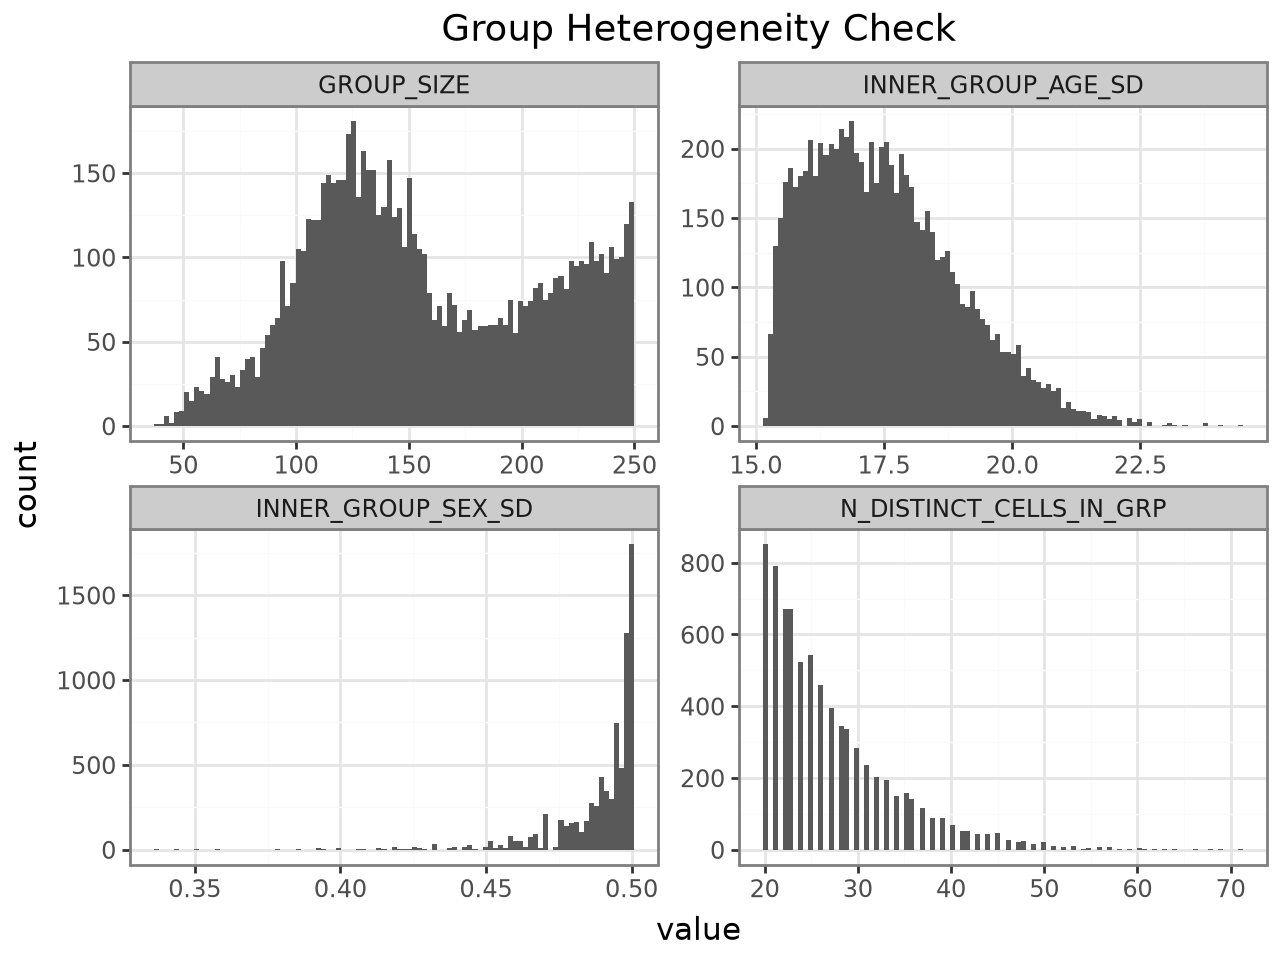

In [10]:
### Check Group Heterogeneity

df_hg_check = df_X_train.groupby("GROUP_ID").agg(
    GROUP_SIZE = pd.NamedAgg(column="POLICIES_EXPOSED", aggfunc="sum"),
    N_DISTINCT_CELLS_IN_GRP = pd.NamedAgg(column="OBS_ID", aggfunc="nunique"),
    INNER_GROUP_AGE_SD = pd.NamedAgg(column="ATTAINED_AGE", aggfunc="std"),
    INNER_GROUP_SEX_SD = pd.NamedAgg(column="GENDER", aggfunc=lambda x: np.std([1 if g.upper().strip() == 'MALE' else 0 for g in x]))
)

df_plot = (
    df_hg_check
    .reset_index()
    .melt(
        id_vars=["GROUP_ID"],
        value_vars=["GROUP_SIZE", "N_DISTINCT_CELLS_IN_GRP", "INNER_GROUP_AGE_SD", "INNER_GROUP_SEX_SD"],
        var_name="metric",
        value_name="value"
    )
)

(
    p9.ggplot(df_plot, p9.aes(x="value"))
    + p9.geom_histogram()
    + p9.facet_wrap("~metric", scales="free")
    + p9.theme_bw()
    + p9.labs(title="Group Heterogeneity Check")
)


#### Note about L-BFGS and traditional GLMs (not `glmnet` / `glum`)

Usually, co-linear columns are easy to detect, and model fitting algorithms do it for you.  The real enemy is nearly-colinear columns.  These cause drastic overfitting and long model training times (convergence problems). 

 * `glmnet` and `glum` spoil us by taking care of nearly co-linear columns automatically.  When using other glm fitting algorithms, we need to be careful about nearly co-linear columns (especially when using splines!). 

 * The below function `find_bad_design_columns()` uses a couple common linear algebra operations to look for problems.  It generally works well for simple to medium-complexity models.  It will take a very long time to run on complex models.

In [11]:
from src.lib.grpmodels import find_bad_design_columns

# like the glmnet / glum model, we need to EXCLUDE an intercept (-1 at end).
# we are building the design matrix at an individual level.
X_mmat = frm.model_matrix(
    "cr(ATTAINED_AGE, knots=[30, 50, 60])*GENDER - 1",
    df_X_train)

# run some heuristics to see if any columns are sparse.
# Unlike GLMNET, we don't have any guards against (nearly) collinear columns.
# ALWAYS do this if using splines, and especially when doing splines w/ interactions.
# The model.matrix formula (w/ -1) also introduces a term that will be colinear with the intercept, so we need to remove it.  
bad_cols = find_bad_design_columns(X_mmat)

print(f"Found {len(bad_cols)} bad columns: {bad_cols}")

Found 3 bad columns: ['GENDER[FEMALE]', 'GENDER[MALE]', 'cr(ATTAINED_AGE, knots=[30, 50, 60])[4]']


In [12]:
from src.lib.grpmodels import GroupedPoissonGLM

# remember, we need to provide the exposure / offset at the individual level
X_fit_train = pd.concat([
     df_X_train[["GROUP_ID", "POLICIES_EXPOSED"]],
     X_mmat.drop(columns=bad_cols)
], axis=1)

# always take the log of the offset column
X_fit_train["log_POLICIES_EXPOSED"] = np.log(X_fit_train["POLICIES_EXPOSED"])

# define the model structure. GroupedPoissonGLM() has more parameters, but the
# defaults are usually fine.  maxiter is set to 10,000 to ensure convergence, 
# since we are using splines and interactions.
model = GroupedPoissonGLM(
    y_col="GROUP_CLAIM_COUNT", 
    offset_col="log_POLICIES_EXPOSED", 
    maxiter = 10_000)

# fit INDIVIDUAL level betas using a GROUPED response
model_fit = model.fit(
    X_fit_train, 
    df_y_train
)

# after fitting the model, run a sanity check to make sure
# that we are seeing 100% A/E with the model's predictions (checks convergence)
df_pred_grouped = (
    model_fit
    # we are prodiving group-level model predictions, we'll do individual next!
    .predict_group_mu(X_fit_train)
    .merge(df_y_train, how="inner", on="GROUP_ID")
)

# A/E sanity check for convergence (should be very close to 1)
df_pred_grouped["MODEL_PRED"] = df_pred_grouped["mu_group"] 
df_pred_grouped["GROUP_CLAIM_COUNT"].sum() / df_pred_grouped["MODEL_PRED"].sum()

np.float64(0.9999999999999999)

Running query in 'duckdb:///:memory:'

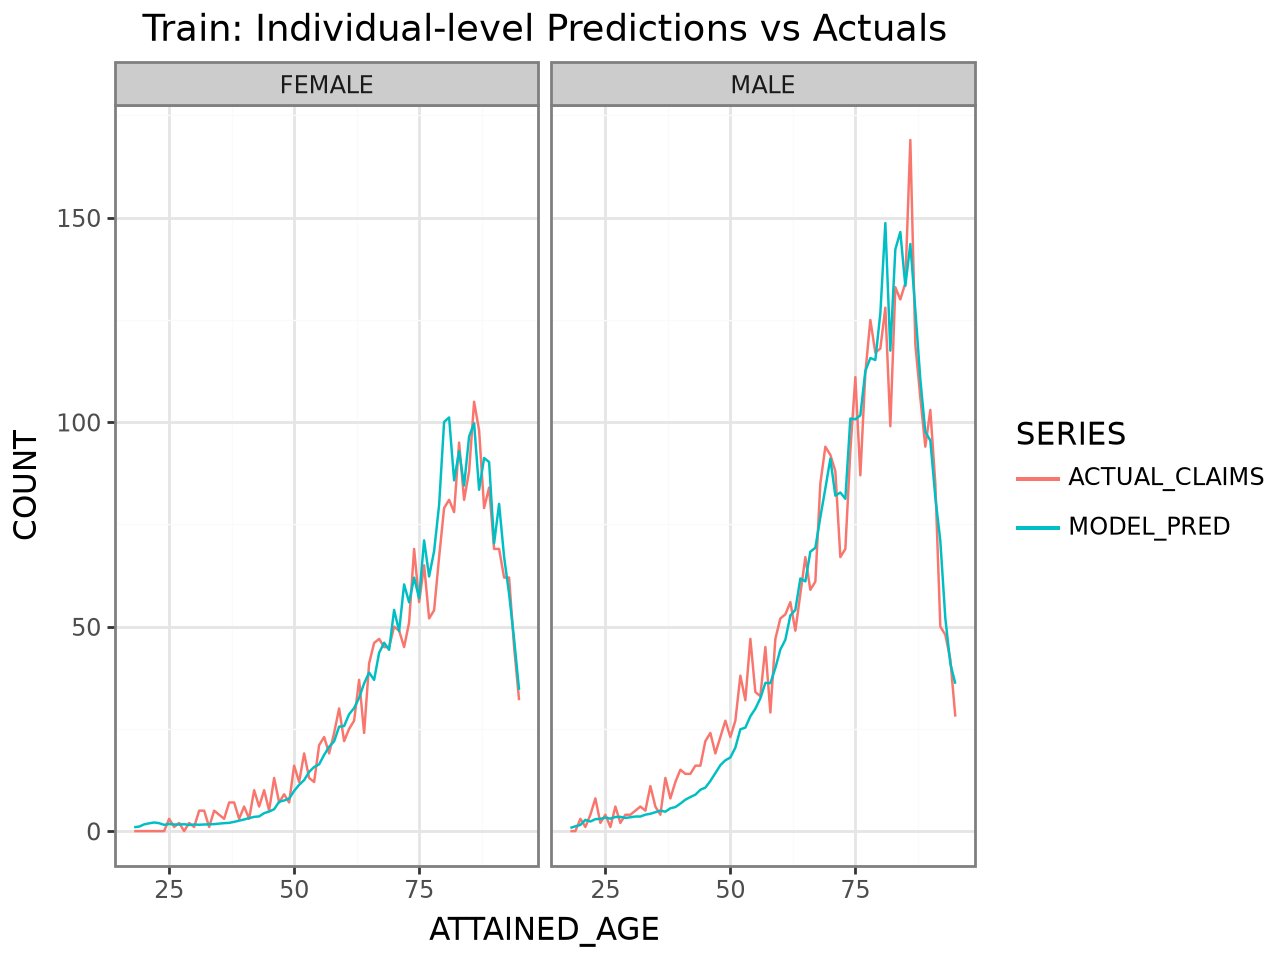

In [13]:
# let's get the ACTUAL individual claims (unseen by model)
df_check_train_preds = %sql select V.* from V_SERIATIM V inner join V_TT_SPLIT T on V.GROUP_ID = T.GROUP_ID where T.TRAIN_IND = 1
df_check_train_preds = df_check_train_preds.DataFrame()

# ALWAYS reuse the model_matrix / model_spec from fitting.
# DON'T recreate the model matrix with a string when using splines
model_spec = X_mmat.model_spec

# calculate design matrix. 
X_check_train_preds = pd.concat([
     df_check_train_preds[["GROUP_ID", "POLICIES_EXPOSED"]],
     model_spec.get_model_matrix(df_check_train_preds).drop(columns=bad_cols)
], axis=1)

# remember to calculate the log of the offset column
X_check_train_preds["log_POLICIES_EXPOSED"] = np.log(X_check_train_preds["POLICIES_EXPOSED"])

# add individual model predictions to the individual-level data frame.  
df_check_train_preds["MODEL_PRED"] = model_fit.predict_individual_mu(X_check_train_preds)

# plotnine, like ggplot in R, is very opinioned about the shape of data that you give it,
# when plotting two series (actual claim counts vs. predicted claims counts), it's easiest
# to pivot the data into a long format (.melt())
df_plot_data = (
    df_check_train_preds
    .groupby(["ATTAINED_AGE", "GENDER"])
    .agg(
        ACTUAL_CLAIMS = pd.NamedAgg(column="CLAIM_COUNT", aggfunc="sum"),
        MODEL_PRED = pd.NamedAgg(column="MODEL_PRED", aggfunc="sum")
    )
    .reset_index()
    .melt(
        id_vars=["ATTAINED_AGE", "GENDER"],
        value_vars=["ACTUAL_CLAIMS", "MODEL_PRED"],
        var_name="SERIES",
        value_name="COUNT")
)

import plotnine as p9

(
    p9.ggplot(df_plot_data, p9.aes(x="ATTAINED_AGE", y="COUNT", color="SERIES"))
    + p9.geom_line()
    + p9.facet_wrap("~GENDER")
    + p9.theme_bw()
    + p9.labs(title="Train: Individual-level Predictions vs Actuals")
)


Running query in 'duckdb:///:memory:'

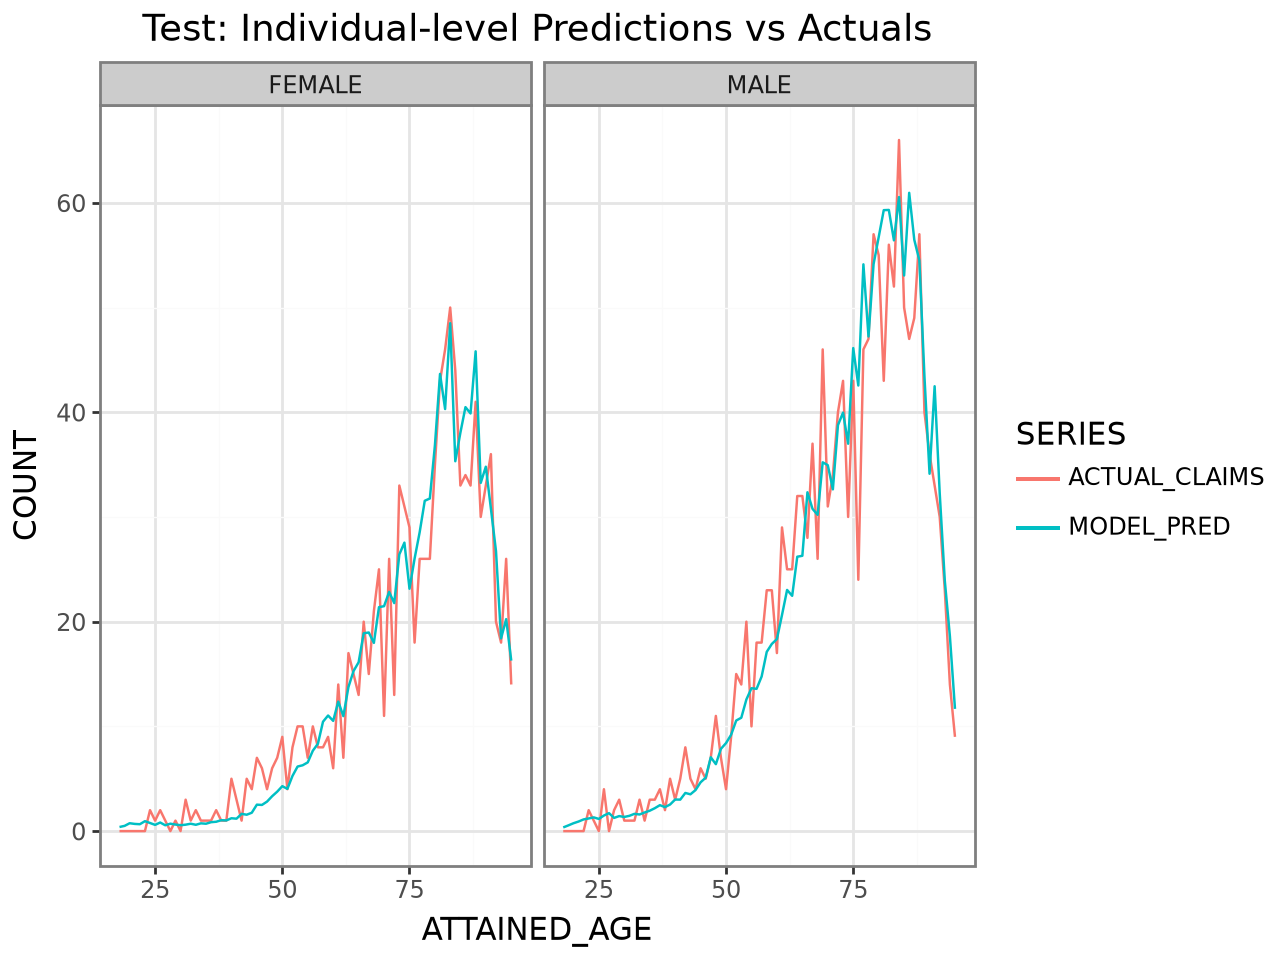

In [14]:
# let's get the OUT-OF-SAMPLE individual claims (unseen by model)
df_check_test_preds = %sql select V.* from V_SERIATIM V inner join V_TT_SPLIT T on V.GROUP_ID = T.GROUP_ID where T.TRAIN_IND = 0
df_check_test_preds = df_check_test_preds.DataFrame()

# ALWAYS reuse the model_matrix / model_spec from fitting WHEN USING SPLINES
# DON'T recreate the model matrix with a string!  Our spline boundaries are 
# set based on the training data, and we need to use the same boundaries for any new data.
model_spec = X_mmat.model_spec

# calculate design matrix. 
X_check_test_preds = pd.concat([
     df_check_test_preds[["GROUP_ID", "POLICIES_EXPOSED"]],
     model_spec.get_model_matrix(df_check_test_preds).drop(columns=bad_cols)
], axis=1)

# remember to calculate the log of the offset column
X_check_test_preds["log_POLICIES_EXPOSED"] = np.log(X_check_test_preds["POLICIES_EXPOSED"])

# add individual model predictions to the individual-level data frame.  
df_check_test_preds["MODEL_PRED"] = model_fit.predict_individual_mu(X_check_test_preds)

# plotnine, like ggplot in R, is very opinioned about the shape of data that you give it,
# when plotting two series (actual claim counts vs. predicted claims counts), it's easiest
# to pivot the data into a long format (.melt())
df_plot_data = (
    df_check_test_preds
    .groupby(["ATTAINED_AGE", "GENDER"])
    .agg(
        ACTUAL_CLAIMS = pd.NamedAgg(column="CLAIM_COUNT", aggfunc="sum"),
        MODEL_PRED = pd.NamedAgg(column="MODEL_PRED", aggfunc="sum")
    )
    .reset_index()
    .melt(
        id_vars=["ATTAINED_AGE", "GENDER"],
        value_vars=["ACTUAL_CLAIMS", "MODEL_PRED"],
        var_name="SERIES",
        value_name="COUNT")
)

import plotnine as p9

(
    p9.ggplot(df_plot_data, p9.aes(x="ATTAINED_AGE", y="COUNT", color="SERIES"))
    + p9.geom_line()
    + p9.facet_wrap("~GENDER")
    + p9.theme_bw()
    + p9.labs(title="Test: Individual-level Predictions vs Actuals")
)


### Comparison to individual-level GLM

There is some variance in the coefficients, but in order to assess the materiality, we'll need to build a full mortality table using both models.

In [15]:
import statsmodels.api as sm

# design matrix, offset, and response (individual model)
X_sm = model_spec.get_model_matrix(df_check_test_preds).drop(columns=bad_cols)

# need to add an intercept column for statsmodels GLM
X_sm = sm.add_constant(X_sm, has_constant="add")

offset_sm = np.log(df_check_test_preds["POLICIES_EXPOSED"].astype(float))
y_sm = df_check_test_preds["CLAIM_COUNT"].astype(float)

# fit individual-level Poisson GLM with offset
glm_sm = sm.GLM(
    y_sm,
    X_sm,
    family=sm.families.Poisson(),
    offset=offset_sm,
)
glm_sm_fit = glm_sm.fit(maxiter=10_000)

# compare coefficients against GroupedPoissonGLM
feature_cols = X_sm.columns.drop('const').tolist()
coef_compare = pd.DataFrame({
    "term": ["intercept"] + feature_cols,
    "statsmodels_coef": [glm_sm_fit.params["const"]] + [glm_sm_fit.params[c] for c in feature_cols],
    "grouped_poisson_coef": [model_fit.intercept_] + [model_fit.coef_[c] for c in feature_cols],
})

coef_compare["abs_diff"] = (coef_compare["statsmodels_coef"] - coef_compare["grouped_poisson_coef"]).abs()
coef_compare.sort_values("abs_diff", ascending=False).reset_index(drop=True)

,term,statsmodels_coef,grouped_poisson_coef,abs_diff
0,"cr(ATTAINED_AGE, knots=[30, 50, 60])[1]",-2.479641,-0.817257,1.662384
1,"cr(ATTAINED_AGE, knots=[30, 50, 60])[1]:GENDER...",0.368179,-0.244858,0.613038
2,"cr(ATTAINED_AGE, knots=[30, 50, 60])[2]",-2.264417,-2.762950,0.498533
3,"cr(ATTAINED_AGE, knots=[30, 50, 60])[2]:GENDER...",0.124894,0.613651,0.488758
4,"cr(ATTAINED_AGE, knots=[30, 50, 60])[3]",-0.850458,-1.161257,0.310798
5,"cr(ATTAINED_AGE, knots=[30, 50, 60])[5]:GENDER...",0.167659,0.334550,0.166892
6,"cr(ATTAINED_AGE, knots=[30, 50, 60])[3]:GENDER...",0.206816,0.361955,0.155139
7,intercept,-5.841040,-5.897159,0.056119
8,"cr(ATTAINED_AGE, knots=[30, 50, 60])[5]",4.299763,4.340023,0.040259
9,"cr(ATTAINED_AGE, knots=[30, 50, 60])[4]:GENDER...",0.302042,0.269520,0.032522


### Grouped Model Mortality Table

The `PoissonGLMFactorAnalysis()` is a general purpose utility that takes coefficients and a `formulaic` design matrix.  It makes "human-friendly" interpretations of the resulting model output, broken down by **predictor** rather than design matrix term.

  * For example, with splines, we need to evaluate multiple columns to understand the shape of the prediction.  `PoissonGLMFactorAnalysis()` does this for us automatically, but it might need to be manually nudged in for complex use cases.

  * The biggest difference is for younger females, where claims are likely quite thin.

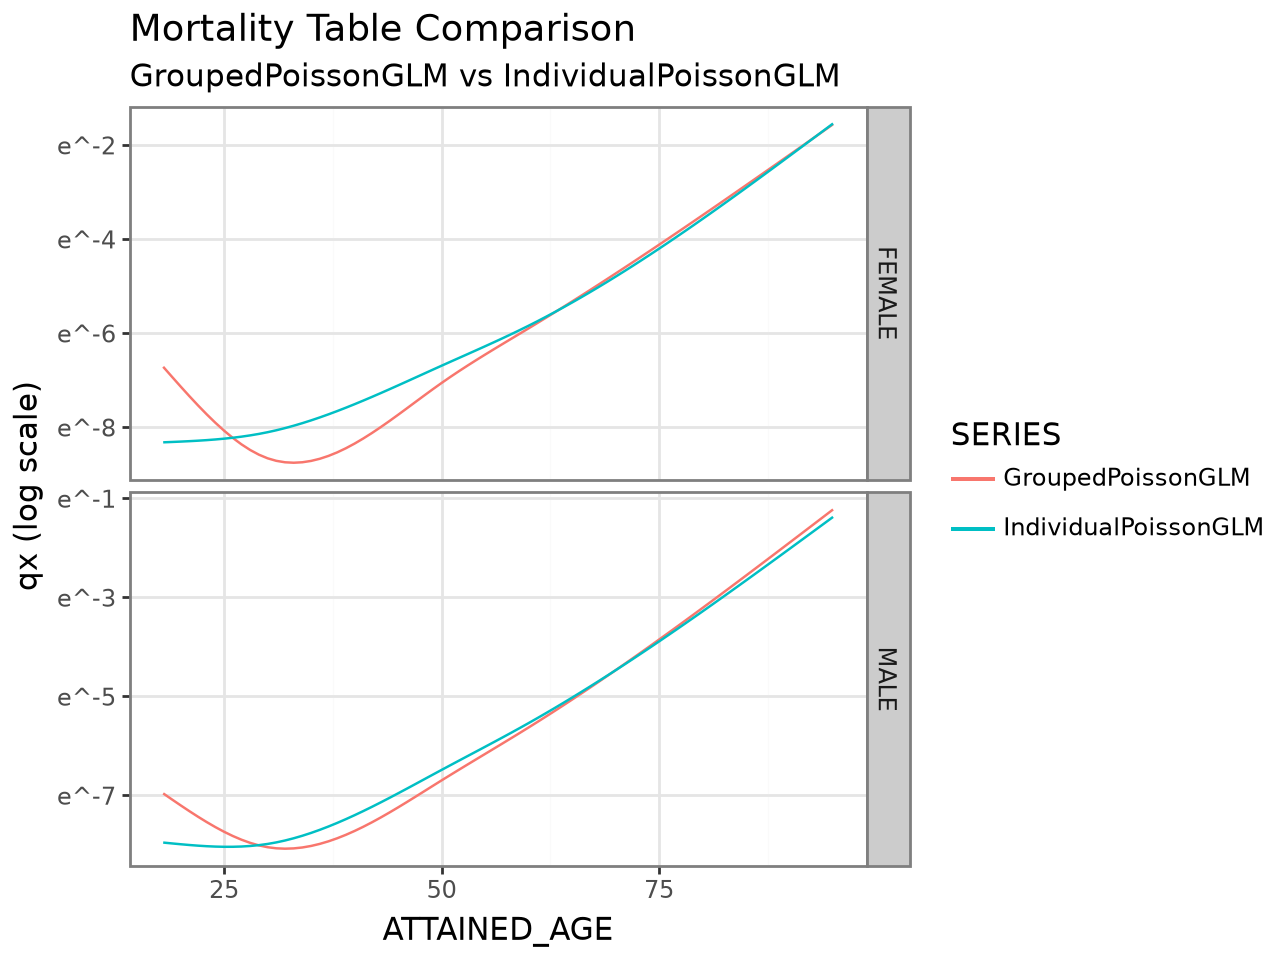

In [16]:
from src.lib.glm import PoissonGLMFactorAnalysis

# helper to create mortality tables for both models
def get_mort_table(coef_table, model_spec, df_check_test_preds):

    # add back "bad_cols" with a zero coefficient, since they were dropped from the model matrix.  
    # This is important for the factor analysis to work correctly.
    for col in bad_cols:
        coef_table[col] = 0.0

    factor_analysis = PoissonGLMFactorAnalysis(coef_table, model_spec)
    factor_table = factor_analysis.get_factor_analysis(df_check_test_preds)
    
    base_mort_rate = factor_table[0]["factor"][0]
    mort_table = factor_table[1]
    mort_table.rename(columns={"factor": "age_sex_factor"}, inplace=True)
    mort_table["qx"] = base_mort_rate * mort_table["age_sex_factor"]
    return mort_table


# create the coefficient table for the grouped model
grouped_model_coef = coef_compare["grouped_poisson_coef"].rename("coef")
grouped_model_coef.index = coef_compare["term"].values
grouped_mort_table = get_mort_table(grouped_model_coef, model_spec, df_check_test_preds)
grouped_mort_table["SERIES"] = "GroupedPoissonGLM"

ind_model_coef = coef_compare["statsmodels_coef"].rename("coef")
ind_model_coef.index = coef_compare["term"].values
ind_mort_table = get_mort_table(ind_model_coef, model_spec, df_check_test_preds)
ind_mort_table["SERIES"] = "IndividualPoissonGLM"

# create a table for plotting
df_mort_table_compare = pd.concat(
    [grouped_mort_table, ind_mort_table],
    ignore_index=True,
    axis=0
)

(
    p9.ggplot(df_mort_table_compare, p9.aes(x="ATTAINED_AGE", y="qx", color="SERIES"))
    + p9.facet_grid("GENDER~.", scales="free_y")
    + p9.geom_line()
    + p9.theme_bw()
    + p9.scale_y_continuous(trans="log")
    + p9.labs(title="Mortality Table Comparison", subtitle="GroupedPoissonGLM vs IndividualPoissonGLM", y="qx (log scale)"  )
)


### Stepwise Variable Selection

There are practical complications with running a LASSO on the GroupedPoissonGLM.  This is a limitation of L-BFGS-B on this type of problem. So the next best thing is step-wise variable selection.

The class `StepWiseGroupedPoissonGLM` provides the following procedure:

 1. Starting with a *base* design matrix, add a single term / variable and fit the model.

 2. Record the change in AIC/BIC/NLL. 

 3. Repeat this for all features, and add the feature to the model that resulted in the largest change in AIC/BIC/NLL.

If you give this a lot of features, it will be slow, but we can use a few tricks (warm-starts and pruning).  

 * Warm-starts are somewhat of an implementation detail, but it might be a good idea to refit the final model using a plain `GroupedPoissonGLM`.  There is also a possibility that the you get nonsense coefficients. 

 * Pruning retains the top N% of features after the first round to try fitting subsequent rounds to.



In [17]:
# build terms (candidates to add)
stepwise_terms = []

# not worried about colinearity here, since we are using a step-wise model selection process.  We will let the model
for grp in df_X_train.FACE_AMOUNT_GRP.unique():
    stepwise_terms.append(f"{{FACE_AMOUNT_GRP == '{grp}'}} - 1")

df_X_train["PREF_CLASS_AND_STRUCT"] = (
    df_X_train["PREFERRED_CLASS"].astype(str)
    + ":"
    + df_X_train["NUMBER_OF_PREFERRED_CLASSES"].astype(str)
)

for grp in df_X_train.PREF_CLASS_AND_STRUCT.unique():
    stepwise_terms.append(f"{{PREF_CLASS_AND_STRUCT == '{grp}'}} - 1")

stepwise_terms.append("log(pmin(DURATION, 20)) - 1")

stepwise_terms

["{FACE_AMOUNT_GRP == 'C. 50000-99999'} - 1",
 "{FACE_AMOUNT_GRP == 'D. 100000-249999'} - 1",
 "{FACE_AMOUNT_GRP == 'E. 250000-499999'} - 1",
 "{FACE_AMOUNT_GRP == 'F. 500000-999999'} - 1",
 "{FACE_AMOUNT_GRP == 'B. 25000-49999'} - 1",
 "{FACE_AMOUNT_GRP == 'G. 1000000-2499999'} - 1",
 "{FACE_AMOUNT_GRP == 'H. 2500000+'} - 1",
 "{FACE_AMOUNT_GRP == 'A. 1-24999'} - 1",
 "{PREF_CLASS_AND_STRUCT == '1:2'} - 1",
 "{PREF_CLASS_AND_STRUCT == '2:2'} - 1",
 "{PREF_CLASS_AND_STRUCT == '1:3'} - 1",
 "{PREF_CLASS_AND_STRUCT == '3:4'} - 1",
 "{PREF_CLASS_AND_STRUCT == '4:4'} - 1",
 "{PREF_CLASS_AND_STRUCT == '3:3'} - 1",
 "{PREF_CLASS_AND_STRUCT == '2:3'} - 1",
 "{PREF_CLASS_AND_STRUCT == '1:4'} - 1",
 "{PREF_CLASS_AND_STRUCT == '2:4'} - 1",
 'log(pmin(DURATION, 20)) - 1']

In [19]:
from src.lib.grpmodels import StepWiseGroupedPoissonGLM

# Reuse the already-fitted base design matrix columns (no patsy/model_matrix rebuild).
base_feature_cols = list(model_fit.feature_cols_)

# Build stepwise input from the fitted base design matrix plus the raw columns used by eval_terms.
# Keep only GROUP_ID, offset, and base_feature_cols as the always-on model terms.
X_fit_train_stepwise = pd.concat([
    df_X_train[["GROUP_ID"]],
    pd.DataFrame({
        "log_POLICIES_EXPOSED": np.log(df_X_train["POLICIES_EXPOSED"].astype(float))
    }, index=df_X_train.index),
    X_fit_train[base_feature_cols],
    df_X_train[["FACE_AMOUNT_GRP", "PREF_CLASS_AND_STRUCT", "DURATION"]],
], axis=1)

stepwise_model = StepWiseGroupedPoissonGLM(
    y_col="GROUP_CLAIM_COUNT",
    offset_col="log_POLICIES_EXPOSED",
    feature_cols=base_feature_cols,
    eval_terms=stepwise_terms,
    context={"pmin": np.minimum},  # used by log(pmin(DURATION, 20))
    pct_retained=50.0,
    selection_metric="nll", # aic | bic | nll (default to bic)
    min_selection_change=0.0, # should be greater than or equal to zero to avoid numerical stability issues
    maxiter=10_000,
    verbose=True,
)

# Warm-start with full theta vector (includes intercept at index 'intercept').
prev_model_coef = model_fit.theta_.copy()

stepwise_fit = stepwise_model.fit(
    X_fit_train_stepwise,
    df_y_train,
    warm_start=prev_model_coef,
    n_round=6,
)

stepwise_model.steps()

Initial model NLL: 6515.716328
Round 1: best term={PREF_CLASS_AND_STRUCT == '2:2'} - 1 nll_change=10.896026 retained=["{PREF_CLASS_AND_STRUCT == '2:2'} - 1", "{FACE_AMOUNT_GRP == 'A. 1-24999'} - 1", "{PREF_CLASS_AND_STRUCT == '3:3'} - 1", 'log(pmin(DURATION, 20)) - 1', "{PREF_CLASS_AND_STRUCT == '1:2'} - 1", "{PREF_CLASS_AND_STRUCT == '1:3'} - 1", "{FACE_AMOUNT_GRP == 'D. 100000-249999'} - 1", "{FACE_AMOUNT_GRP == 'F. 500000-999999'} - 1", "{FACE_AMOUNT_GRP == 'E. 250000-499999'} - 1"]
Accepted term {PREF_CLASS_AND_STRUCT == '2:2'} - 1; current NLL=6504.820302
Round 2: best term={FACE_AMOUNT_GRP == 'A. 1-24999'} - 1 nll_change=2.398711 retained=["{FACE_AMOUNT_GRP == 'A. 1-24999'} - 1", "{PREF_CLASS_AND_STRUCT == '1:2'} - 1", "{PREF_CLASS_AND_STRUCT == '1:3'} - 1", 'log(pmin(DURATION, 20)) - 1', "{PREF_CLASS_AND_STRUCT == '3:3'} - 1", "{FACE_AMOUNT_GRP == 'D. 100000-249999'} - 1", "{FACE_AMOUNT_GRP == 'F. 500000-999999'} - 1", "{FACE_AMOUNT_GRP == 'E. 250000-499999'} - 1"]
Accepted term

,round,term,selection_metric,current_score,candidate_score,score_change,optimizer_success,n_terms_selected,n_candidates_evaluated,n_candidates_retained
0,1,{PREF_CLASS_AND_STRUCT == '2:2'} - 1,nll,6515.716328,6504.820302,10.896026,True,1,18,9
1,2,{FACE_AMOUNT_GRP == 'A. 1-24999'} - 1,nll,6504.820302,6502.421591,2.398711,True,2,8,9
2,3,{PREF_CLASS_AND_STRUCT == '1:2'} - 1,nll,6502.421591,6498.576338,3.845254,True,3,7,9
3,4,{PREF_CLASS_AND_STRUCT == '1:3'} - 1,nll,6498.576338,6491.375504,7.200834,True,4,6,9
4,5,{FACE_AMOUNT_GRP == 'F. 500000-999999'} - 1,nll,6491.375504,6490.746854,0.628650,True,5,5,9
5,6,"log(pmin(DURATION, 20)) - 1",nll,6490.746854,6490.248795,0.498059,True,6,4,9


### Wrap-up and Key Takeaways

 * We can fit individual level models from grouped data, provided we have individual-level predictors / exposures (e.g., a census).

 * L-BFGS-B is a powerful optimization method that is available in many places (R, Python, etc.).  It's fast, stable, scalable (via JAX), and allows for bounded coefficients.  On rare occassions that we need a customized fit, it is our default tool. 